# THỰC HÀNH TUẦN 2A — NAIVE BAYES

**Họ và tên:** Trần Đức Vũ Hào  
**Nội dung:** Gaussian Naive Bayes, Multinomial Naive Bayes và Bernoulli Naive Bayes

Notebook này giải toàn bộ các yêu cầu trong `thuchanh_bai1_NaiveBayes.pdf` bằng một quy trình thống nhất:

1. hiểu dữ liệu và chọn đúng biến thể Naive Bayes;
2. chia train/test trước khi học mọi tham số từ dữ liệu;
3. huấn luyện mô hình;
4. đánh giá bằng chỉ số phù hợp và giải thích kết quả.

> **Ý tưởng cốt lõi:** Naive Bayes giả sử các đặc trưng độc lập có điều kiện khi đã biết lớp. Giả sử này thường không hoàn toàn đúng, nhưng giúp ta biến một xác suất nhiều chiều khó tính thành tích của nhiều xác suất một chiều dễ tính.

## 0. Công thức chung và cách chọn mô hình

Với mẫu có các đặc trưng $x=(x_1,\ldots,x_d)$, ta chọn lớp có hậu nghiệm lớn nhất:

$$
\hat y=\arg\max_c P(c\mid x)
=\arg\max_c P(c)\prod_{j=1}^{d}P(x_j\mid c).
$$

- **GaussianNB:** $x_j$ là số liên tục. Trong mỗi lớp, mỗi đặc trưng được mô hình bằng phân phối chuẩn với trung bình $\mu_{cj}$ và phương sai $\sigma^2_{cj}$.
- **MultinomialNB:** $x_j$ là số lần xuất hiện/giá trị đếm không âm, điển hình là số từ trong văn bản.
- **BernoulliNB:** $x_j\in\{0,1\}$, diễn tả một dấu hiệu có hay không.

Trong tính toán, ta cộng **log-xác suất** thay vì nhân nhiều số rất nhỏ:

$$
\log P(c\mid x) \propto \log P(c)+\sum_j \log P(x_j\mid c).
$$

Laplace smoothing với `alpha=1` giúp xác suất không bị bằng 0 khi một từ/giá trị chưa xuất hiện ở một lớp trong tập train.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.preprocessing import OneHotEncoder

SEED = 2026
DATA_DIR = Path.cwd()


def metric_row(problem, y_true, y_pred, average="macro"):
    # Trả về một dòng chỉ số để cuối bài có thể tổng hợp nhất quán.
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average=average, zero_division=0
    )
    return {
        "Bài toán": problem,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
    }


results = []
print("Thư mục dữ liệu:", DATA_DIR)
print("Random seed:", SEED)

Thư mục dữ liệu: D:\MachineLearning\Week2
Random seed: 2026


## 1. Iris — GaussianNB với đủ 4 đặc trưng

### Vì sao dùng GaussianNB?

Bốn đại lượng chiều dài/rộng của đài hoa và cánh hoa đều là số liên tục. GaussianNB học riêng $\mu$ và $\sigma^2$ của từng đặc trưng trong từng loài, sau đó so sánh tổng log-xác suất của ba loài.

Theo đề, ta dùng đủ 4 đặc trưng và chia **train:test = 4:1**. `stratify=y` giữ tỷ lệ ba loài cân bằng ở cả hai tập.

In [2]:
iris = pd.read_csv(DATA_DIR / "iris.csv")
iris_features = ["sepal.length", "sepal.width", "petal.length", "petal.width"]
X_iris = iris[iris_features].to_numpy(float)
y_iris = iris["variety"].to_numpy()

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.20,
    random_state=SEED,
    stratify=y_iris,
)

print("Kích thước train/test:", Xi_train.shape, Xi_test.shape)
print("Số mẫu mỗi lớp ở test:")
print(pd.Series(yi_test).value_counts().sort_index())

Kích thước train/test: (120, 4) (30, 4)
Số mẫu mỗi lớp ở test:
Setosa        10
Versicolor    10
Virginica     10
Name: count, dtype: int64


In [3]:
class GaussianNBFromScratch:
    # Bản cài đặt tối giản để nhìn thấy chính xác GaussianNB học gì.

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.mean_ = np.vstack([X[y == label].mean(axis=0) for label in self.classes_])
        self.var_ = np.vstack([X[y == label].var(axis=0) for label in self.classes_])
        self.prior_ = np.array([(y == label).mean() for label in self.classes_])
        # Một lượng rất nhỏ tránh chia cho 0 nếu đặc trưng trong một lớp là hằng số.
        self.var_ += 1e-9 * np.var(X, axis=0).max()
        return self

    def _joint_log_likelihood(self, X):
        scores = []
        for class_index in range(len(self.classes_)):
            mean = self.mean_[class_index]
            var = self.var_[class_index]
            log_density = -0.5 * (np.log(2 * np.pi * var) + (X - mean) ** 2 / var)
            scores.append(np.log(self.prior_[class_index]) + log_density.sum(axis=1))
        return np.column_stack(scores)

    def predict(self, X):
        best_class_index = self._joint_log_likelihood(X).argmax(axis=1)
        return self.classes_[best_class_index]


scratch_iris = GaussianNBFromScratch().fit(Xi_train, yi_train)
library_iris = GaussianNB().fit(Xi_train, yi_train)

pred_iris_scratch = scratch_iris.predict(Xi_test)
pred_iris_library = library_iris.predict(Xi_test)

print(f"Accuracy tự cài đặt : {accuracy_score(yi_test, pred_iris_scratch):.4f}")
print(f"Accuracy thư viện   : {accuracy_score(yi_test, pred_iris_library):.4f}")
print("Hai cách dự đoán giống nhau:", np.array_equal(pred_iris_scratch, pred_iris_library))
print("\nBáo cáo GaussianNB thư viện:")
print(classification_report(yi_test, pred_iris_library, zero_division=0))

results.append(metric_row("Iris — GaussianNB", yi_test, pred_iris_library))

Accuracy tự cài đặt : 0.9333
Accuracy thư viện   : 0.9333
Hai cách dự đoán giống nhau: True

Báo cáo GaussianNB thư viện:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



**Đọc kết quả:** Accuracy cho biết tỷ lệ dự đoán đúng chung. Precision trả lời “trong các mẫu mô hình gọi là lớp này, bao nhiêu mẫu đúng?”, còn Recall trả lời “trong các mẫu thật sự thuộc lớp này, mô hình tìm được bao nhiêu?”. F1 là trung bình điều hòa của Precision và Recall.

## 2. Wisconsin Breast Cancer — chọn đúng 80 mẫu lành và 40 mẫu ác

Dữ liệu gốc có 11 cột: mã mẫu, 9 đặc trưng chẩn đoán và nhãn lớp cuối cùng (`2` = lành tính, `4` = ác tính). Mã mẫu chỉ là định danh nên **không được dùng làm đặc trưng**.

Quy trình tránh rò rỉ dữ liệu:

1. lấy ngẫu nhiên đúng 80 mẫu lớp 2 và 40 mẫu lớp 4 cho test;
2. phần còn lại là train;
3. chỉ dùng trung vị của **tập train** để điền dấu `?`;
4. dùng đúng trung vị đó để biến đổi tập test.

Không điền thiếu “theo lớp” vì lúc dự đoán thực tế ta chưa biết lớp của bệnh nhân mới.

In [4]:
cancer_columns = [
    "sample_id", "clump_thickness", "uniform_cell_size", "uniform_cell_shape",
    "marginal_adhesion", "single_epithelial_size", "bare_nuclei",
    "bland_chromatin", "normal_nucleoli", "mitoses", "class",
]
cancer = pd.read_csv(
    DATA_DIR / "breast-cancer-wisconsin.data",
    header=None,
    names=cancer_columns,
    na_values="?",
)
cancer_features = [c for c in cancer_columns if c not in {"sample_id", "class"}]

rng = np.random.default_rng(SEED)
test_index = np.concatenate([
    rng.choice(cancer.index[cancer["class"] == 2], size=80, replace=False),
    rng.choice(cancer.index[cancer["class"] == 4], size=40, replace=False),
])

cancer_test = cancer.loc[test_index].copy()
cancer_train = cancer.drop(index=test_index).copy()

train_medians = cancer_train[cancer_features].median(numeric_only=True)
cancer_train[cancer_features] = cancer_train[cancer_features].fillna(train_medians)
cancer_test[cancer_features] = cancer_test[cancer_features].fillna(train_medians)

Xc_train = cancer_train[cancer_features].to_numpy(float)
yc_train = cancer_train["class"].to_numpy()
Xc_test = cancer_test[cancer_features].to_numpy(float)
yc_test = cancer_test["class"].to_numpy()

print("Số dấu ? trong dữ liệu gốc:", int(cancer[cancer_features].isna().sum().sum()))
print("Train/Test:", len(cancer_train), "/", len(cancer_test))
print("Phân bố test:", pd.Series(yc_test).value_counts().sort_index().to_dict())
print("Còn giá trị thiếu sau xử lý:", np.isnan(Xc_train).sum() + np.isnan(Xc_test).sum())

Số dấu ? trong dữ liệu gốc: 16
Train/Test: 579 / 120
Phân bố test: {2: 80, 4: 40}
Còn giá trị thiếu sau xử lý: 0


In [5]:
cancer_model = GaussianNB().fit(Xc_train, yc_train)
pred_cancer = cancer_model.predict(Xc_test)

print(classification_report(
    yc_test,
    pred_cancer,
    labels=[2, 4],
    target_names=["Lành tính (2)", "Ác tính (4)"],
    zero_division=0,
))

malignant_report = classification_report(
    yc_test, pred_cancer, labels=[2, 4], output_dict=True, zero_division=0
)
print(f"Recall lớp ác tính (4): {malignant_report['4']['recall']:.4f}")
print("Trong sàng lọc, recall ác tính đáng chú ý vì bỏ sót ca ác tính có hậu quả lớn.")

results.append(metric_row("Breast Cancer — GaussianNB", yc_test, pred_cancer))

               precision    recall  f1-score   support

Lành tính (2)       0.97      0.93      0.95        80
  Ác tính (4)       0.86      0.95      0.90        40

     accuracy                           0.93       120
    macro avg       0.92      0.94      0.93       120
 weighted avg       0.94      0.93      0.93       120

Recall lớp ác tính (4): 0.9500
Trong sàng lọc, recall ác tính đáng chú ý vì bỏ sót ca ác tính có hậu quả lớn.


## 3. Văn bản ẩm thực Bắc/Nam — MultinomialNB và BernoulliNB

Ta tạo vector trực tiếp từ câu gốc để tránh nhập nhầm ma trận:

- **Multinomial:** giữ số lần xuất hiện; ví dụ “Hà-Nội” xuất hiện 2 lần trong D1.
- **Bernoulli:** chỉ giữ 0/1; xuất hiện một hay nhiều lần đều được tính là “có”.

Tập train rất nhỏ (3 văn bản Bắc, 1 văn bản Nam), nên `alpha=1` là cần thiết. Kết quả chỉ minh họa cách thuật toán hoạt động, chưa đủ để kết luận chất lượng ngoài thực tế.

In [6]:
vocabulary = [
    "hà-nội", "phở", "cháo-lòng", "bún-chả", "ô-mai",
    "bánh-giò", "sài-gòn", "hủ-tiếu", "bánh-bò",
]

train_documents = [
    "Hà-Nội phở cháo-lòng Hà-Nội",
    "Hà-Nội bún-chả phở ô-mai",
    "Phở bánh-giò ô-mai",
    "Sài-gòn hủ-tiếu bánh-bò phở",
]
train_regions = np.array(["B", "B", "B", "N"])
test_documents = [
    "Hà-Nội Hà-Nội bún-chả hủ-tiếu",
    "phở hủ-tiếu bánh-bò",
]


def count_vectors(documents, vocabulary):
    rows = []
    for document in documents:
        counts = Counter(document.lower().split())
        rows.append([counts[token] for token in vocabulary])
    return np.asarray(rows, dtype=int)


text_train_counts = count_vectors(train_documents, vocabulary)
text_test_counts = count_vectors(test_documents, vocabulary)

display(pd.DataFrame(text_train_counts, columns=vocabulary, index=["D1", "D2", "D3", "D4"]))
display(pd.DataFrame(text_test_counts, columns=vocabulary, index=["D5", "D6"]))

,hà-nội,phở,cháo-lòng,bún-chả,ô-mai,bánh-giò,sài-gòn,hủ-tiếu,bánh-bò
D1,2,1,1,0,0,0,0,0,0
D2,1,1,0,1,1,0,0,0,0
D3,0,1,0,0,1,1,0,0,0
D4,0,1,0,0,0,0,1,1,1


,hà-nội,phở,cháo-lòng,bún-chả,ô-mai,bánh-giò,sài-gòn,hủ-tiếu,bánh-bò
D5,2,0,0,1,0,0,0,1,0
D6,0,1,0,0,0,0,0,1,1


In [7]:
multinomial_text = MultinomialNB(alpha=1).fit(text_train_counts, train_regions)
bernoulli_text = BernoulliNB(alpha=1).fit((text_train_counts > 0).astype(int), train_regions)

text_models = {
    "MultinomialNB": (
        multinomial_text.predict(text_test_counts),
        multinomial_text.predict_proba(text_test_counts),
        multinomial_text.classes_,
    ),
    "BernoulliNB": (
        bernoulli_text.predict((text_test_counts > 0).astype(int)),
        bernoulli_text.predict_proba((text_test_counts > 0).astype(int)),
        bernoulli_text.classes_,
    ),
}

for model_name, (prediction, probability, class_order) in text_models.items():
    print(f"\n{model_name} — thứ tự xác suất {class_order.tolist()}")
    for doc_name, label, probs in zip(["D5", "D6"], prediction, probability):
        print(f"{doc_name}: lớp {label}, xác suất {np.round(probs, 4)}")


MultinomialNB — thứ tự xác suất ['B', 'N']
D5: lớp B, xác suất [0.8955 0.1045]
D6: lớp N, xác suất [0.2918 0.7082]

BernoulliNB — thứ tự xác suất ['B', 'N']
D5: lớp B, xác suất [0.7655 0.2345]
D6: lớp N, xác suất [0.1695 0.8305]


## 4. Phân loại email spam — dữ liệu thưa 2.500 từ

Mỗi dòng trong tệp đặc trưng có dạng `(email_id, word_id, count)`. Phần lớn từ không xuất hiện trong một email, nên lưu cả ma trận 960 × 2.500 sẽ lãng phí. `coo_matrix` chỉ lưu các ô khác 0.

Theo ví dụ trong đề, mô hình chính là MultinomialNB vì giá trị đặc trưng là **số lần từ xuất hiện**. Ta đồng thời khảo sát 50, 100, 400 và 700 email train để thấy ảnh hưởng của lượng dữ liệu.

Train  50 mẫu -> test accuracy = 0.9731
Train 100 mẫu -> test accuracy = 0.9769
Train 400 mẫu -> test accuracy = 0.9769
Train 700 mẫu -> test accuracy = 0.9808


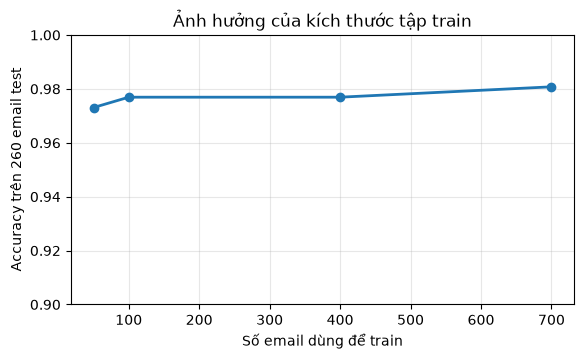

In [8]:
SPAM_DIR = DATA_DIR / "ex6DataPrepared"
VOCAB_SIZE = 2500


def load_sparse_email(feature_file, label_file):
    labels = np.loadtxt(SPAM_DIR / label_file, dtype=int)
    triples = np.loadtxt(SPAM_DIR / feature_file, dtype=int)
    matrix = coo_matrix(
        (triples[:, 2], (triples[:, 0] - 1, triples[:, 1] - 1)),
        shape=(labels.size, VOCAB_SIZE),
    ).tocsr()
    return matrix, labels


spam_test_X, spam_test_y = load_sparse_email("test-features.txt", "test-labels.txt")
spam_sizes = [50, 100, 400, 700]
spam_accuracies = []

for size in spam_sizes:
    suffix = "" if size == 700 else f"-{size}"
    train_X, train_y = load_sparse_email(
        f"train-features{suffix}.txt", f"train-labels{suffix}.txt"
    )
    spam_model = MultinomialNB(alpha=1).fit(train_X, train_y)
    spam_pred = spam_model.predict(spam_test_X)
    spam_accuracies.append(accuracy_score(spam_test_y, spam_pred))
    print(f"Train {size:>3} mẫu -> test accuracy = {spam_accuracies[-1]:.4f}")

# Giữ kết quả mô hình đầy đủ 700 mẫu để đưa vào bảng tổng kết.
results.append(metric_row("Email spam — MultinomialNB", spam_test_y, spam_pred))

plt.figure(figsize=(6.5, 3.5))
plt.plot(spam_sizes, spam_accuracies, marker="o", linewidth=2)
plt.ylim(0.90, 1.00)
plt.xlabel("Số email dùng để train")
plt.ylabel("Accuracy trên 260 email test")
plt.title("Ảnh hưởng của kích thước tập train")
plt.grid(alpha=0.3)
plt.show()

## 5. Đơn hàng trực tuyến — MultinomialNB, train:test = 7:3

Tám đầu vào như thành phố, thiết bị, chương trình khuyến mãi đều là **danh mục**, không phải con số có thứ tự. Vì vậy ta không được tùy tiện mã hóa `city_19` thành 19 rồi khiến mô hình hiểu 19 lớn hơn 1.

`OneHotEncoder` biến mỗi giá trị danh mục thành một cột 0/1. Bộ mã hóa chỉ `fit` trên train, sau đó áp dụng lên test. `handle_unknown='ignore'` giúp một danh mục mới ở test không làm chương trình lỗi.

In [9]:
orders = pd.read_csv(DATA_DIR / "multinomial_nb_orders.csv")
X_orders = orders.drop(columns="cuisine")
y_orders = orders["cuisine"]

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_orders,
    y_orders,
    test_size=0.30,
    random_state=SEED,
    stratify=y_orders,
)

order_encoder = OneHotEncoder(handle_unknown="ignore")
Xo_train_encoded = order_encoder.fit_transform(Xo_train)
Xo_test_encoded = order_encoder.transform(Xo_test)

orders_model = MultinomialNB(alpha=1).fit(Xo_train_encoded, yo_train)
pred_orders = orders_model.predict(Xo_test_encoded)

print("Train/Test:", len(Xo_train), "/", len(Xo_test))
print("Số đặc trưng sau one-hot:", Xo_train_encoded.shape[1])
print(f"Accuracy: {accuracy_score(yo_test, pred_orders):.4f}")
print(classification_report(yo_test, pred_orders, zero_division=0))

results.append(metric_row("Đơn hàng — MultinomialNB", yo_test, pred_orders))

Train/Test: 2100 / 900
Số đặc trưng sau one-hot: 74
Accuracy: 0.5044
               precision    recall  f1-score   support

     american       0.57      0.63      0.60       116
      chinese       0.43      0.64      0.51       119
       indian       0.87      0.93      0.90        88
      italian       0.52      0.57      0.55        93
     japanese       0.31      0.25      0.28        77
       korean       0.36      0.08      0.13        61
mediterranean       0.47      0.30      0.36        71
      mexican       0.68      0.56      0.61        89
         thai       0.39      0.44      0.41        96
   vietnamese       0.34      0.37      0.35        90

     accuracy                           0.50       900
    macro avg       0.49      0.48      0.47       900
 weighted avg       0.50      0.50      0.49       900



## 6. Chẩn đoán từ 30 triệu chứng — BernoulliNB, train:test = 6:4

Mỗi triệu chứng chỉ nhận 0/1 (không/có), nên BernoulliNB phù hợp về mặt biểu diễn. Với từng bệnh, mô hình học xác suất xuất hiện và không xuất hiện của từng triệu chứng.

Đây là dữ liệu thực hành để học thuật toán, **không phải công cụ chẩn đoán y khoa**.

In [10]:
symptoms = pd.read_csv(DATA_DIR / "bernoulli_nb_symptoms.csv")
X_symptoms = symptoms.drop(columns="condition")
y_symptoms = symptoms["condition"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_symptoms,
    y_symptoms,
    test_size=0.40,
    random_state=SEED,
    stratify=y_symptoms,
)

assert set(np.unique(X_symptoms.to_numpy())).issubset({0, 1})

symptom_model = BernoulliNB(alpha=1).fit(Xs_train, ys_train)
pred_symptoms = symptom_model.predict(Xs_test)

print("Train/Test:", len(Xs_train), "/", len(Xs_test))
print(f"Accuracy: {accuracy_score(ys_test, pred_symptoms):.4f}")
print(classification_report(ys_test, pred_symptoms, zero_division=0))

results.append(metric_row("Triệu chứng — BernoulliNB", ys_test, pred_symptoms))

Train/Test: 1500 / 1000
Accuracy: 0.4800
              precision    recall  f1-score   support

     allergy       0.50      0.47      0.49       118
        cold       0.42      0.45      0.43       158
  covid_like       0.53      0.54      0.54       153
 dehydration       0.66      0.59      0.62        94
         flu       0.49      0.54      0.51       153
 food_poison       0.38      0.45      0.41       106
    migraine       0.39      0.36      0.38        94
 stomach_bug       0.51      0.41      0.46       124

    accuracy                           0.48      1000
   macro avg       0.49      0.48      0.48      1000
weighted avg       0.48      0.48      0.48      1000



## 7. So sánh trực quan và tổng kết

Ma trận nhầm lẫn có hàng là lớp thật, cột là lớp dự đoán. Giá trị trên đường chéo là dự đoán đúng; ô ngoài đường chéo cho biết mô hình hay nhầm lớp nào với lớp nào.

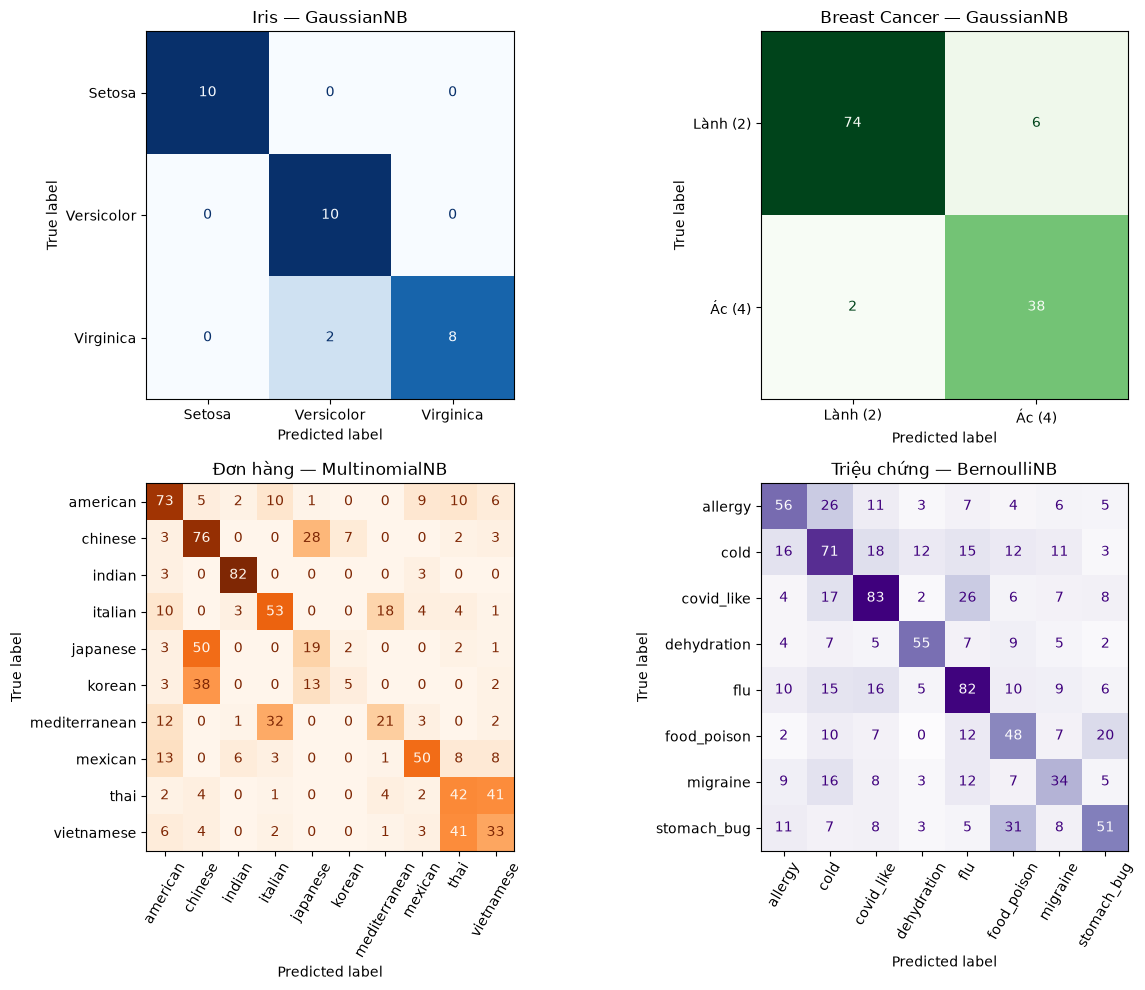

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

ConfusionMatrixDisplay.from_predictions(
    yi_test, pred_iris_library, ax=axes[0, 0], cmap="Blues", colorbar=False
)
axes[0, 0].set_title("Iris — GaussianNB")

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    pred_cancer,
    labels=[2, 4],
    display_labels=["Lành (2)", "Ác (4)"],
    ax=axes[0, 1],
    cmap="Greens",
    colorbar=False,
)
axes[0, 1].set_title("Breast Cancer — GaussianNB")

ConfusionMatrixDisplay.from_predictions(
    yo_test, pred_orders, ax=axes[1, 0], cmap="Oranges", colorbar=False,
    xticks_rotation=60,
)
axes[1, 0].set_title("Đơn hàng — MultinomialNB")

ConfusionMatrixDisplay.from_predictions(
    ys_test, pred_symptoms, ax=axes[1, 1], cmap="Purples", colorbar=False,
    xticks_rotation=60,
)
axes[1, 1].set_title("Triệu chứng — BernoulliNB")

plt.tight_layout()
plt.show()

In [12]:
summary = pd.DataFrame(results)
for column in ["Accuracy", "Precision", "Recall", "F1-score"]:
    summary[column] = summary[column].map(lambda value: f"{value:.2%}")

display(summary)

print("KẾT LUẬN")
print("- GaussianNB phù hợp với số đo liên tục như kích thước hoa và tế bào.")
print("- MultinomialNB phù hợp với dữ liệu đếm/không âm như tần suất từ.")
print("- BernoulliNB phù hợp với trạng thái có/không như triệu chứng.")
print("- Chọn đúng cách biểu diễn dữ liệu quan trọng không kém chọn thuật toán.")

,Bài toán,Accuracy,Precision,Recall,F1-score
0,Iris — GaussianNB,93.33%,94.44%,93.33%,93.27%
1,Breast Cancer — GaussianNB,93.33%,91.87%,93.75%,92.67%
2,Email spam — MultinomialNB,98.08%,98.10%,98.08%,98.08%
3,Đơn hàng — MultinomialNB,50.44%,49.33%,47.60%,47.06%
4,Triệu chứng — BernoulliNB,48.00%,48.59%,47.67%,47.96%


KẾT LUẬN
- GaussianNB phù hợp với số đo liên tục như kích thước hoa và tế bào.
- MultinomialNB phù hợp với dữ liệu đếm/không âm như tần suất từ.
- BernoulliNB phù hợp với trạng thái có/không như triệu chứng.
- Chọn đúng cách biểu diễn dữ liệu quan trọng không kém chọn thuật toán.


## 8. Câu hỏi tự kiểm tra

1. Tại sao phải dùng log-xác suất trong bản GaussianNB tự cài đặt?
2. Vì sao mã bệnh nhân không được dùng làm đặc trưng?
3. Nếu không có Laplace smoothing, chuyện gì xảy ra khi một từ chưa từng xuất hiện ở lớp N?
4. Vì sao one-hot encoding hợp lý hơn gán các danh mục thành số 1, 2, 3, ...?
5. Trong sàng lọc bệnh, tại sao Recall của lớp ác tính có thể quan trọng hơn Accuracy chung?

Nếu trả lời được năm câu này bằng lời của mình, bạn đã nắm được phần “bản chất” quan trọng nhất của bài thực hành.